In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Python environment ready!")

In [ ]:
from pathlib import Path

data_dir = Path("data/raw")

if not data_dir.exists():
    data_dir = Path("../data/raw")

orders = pd.read_csv(
    data_dir / "olist_orders_dataset.csv"
)

print("Dataset shape:", orders.shape)

display(orders.head())

In [5]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

delivered = orders[orders["order_status"] == "delivered"].copy()

stages = [
    ("Purchase to Approval",
     "order_purchase_timestamp", "order_approved_at"),

    ("Approval to Carrier",
     "order_approved_at", "order_delivered_carrier_date"),

    ("Carrier to Customer",
     "order_delivered_carrier_date", "order_delivered_customer_date")
]

stage_samples = {}
results = []

for stage, start, end in stages:

    valid = delivered[[start, end]].dropna()

    duration = (
        valid[end] - valid[start]
    ).dt.total_seconds() / 86400

    duration = duration[duration >= 0]
    stage_samples[stage] = duration

    results.append({
        "Stage": stage,
        "Orders": len(duration),
        "Mean Days": duration.mean(),
        "Median Days": duration.median(),
        "Std Deviation": duration.std(),
        "P90 Days": duration.quantile(0.90),
        "Maximum Days": duration.max(),
        "Orders Over 30 Days": (duration > 30).sum()
    })

eda_results = pd.DataFrame(results)

display(eda_results.round(2))

,Stage,Orders,Mean Days,Median Days,Std Deviation,P90 Days,Maximum Days,Orders Over 30 Days
0,Purchase to Approval,96464,0.43,0.01,0.86,1.44,30.89,2
1,Approval to Carrier,95112,2.85,1.85,3.49,6.02,125.76,177
2,Carrier to Customer,96446,9.33,7.10,8.76,18.90,205.19,2686


In [6]:
sql_reference = {
    "Purchase to Approval": 0.43,
    "Approval to Carrier": 2.85,
    "Carrier to Customer": 9.33
}

eda_results["SQL Mean Days"] = (
    eda_results["Stage"].map(sql_reference)
)

eda_results["Python Mean Days"] = eda_results["Mean Days"].round(2)

eda_results["Validation"] = (
    (eda_results["Python Mean Days"] -
     eda_results["SQL Mean Days"]).abs() <= 0.01
)

display(
    eda_results[
        ["Stage", "SQL Mean Days", "Python Mean Days", "Validation"]
    ]
)

,Stage,SQL Mean Days,Python Mean Days,Validation
0,Purchase to Approval,0.43,0.43,True
1,Approval to Carrier,2.85,2.85,True
2,Carrier to Customer,9.33,9.33,True


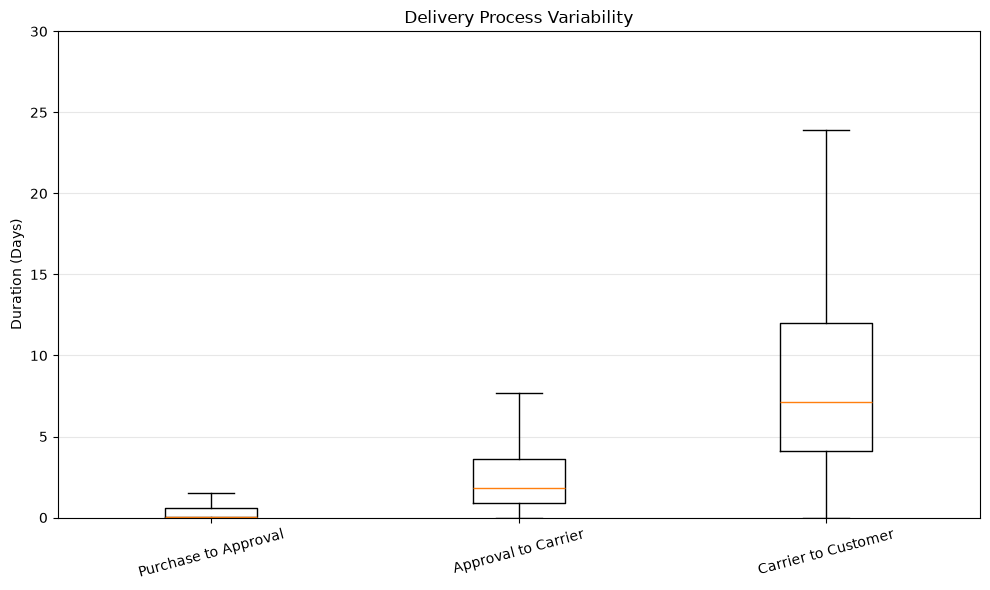

In [7]:
plt.figure(figsize=(10, 6))

plt.boxplot(
    [stage_samples[stage].values for stage, _, _ in stages],
    tick_labels=[stage for stage, _, _ in stages],
    showfliers=False
)

plt.title("Delivery Process Variability")
plt.ylabel("Duration (Days)")
plt.xticks(rotation=15)
plt.ylim(0, 30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()